### Adult dataset: EDA

All 48,842 rows (official train + test sets). To re-run, put `adult.data` and `adult.test` in `data/`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import mutual_info_score, normalized_mutual_info_score

from preprocessing import FEATURES, load_adult, to_categories

train, test = load_adult()
df = pd.concat([train, test], ignore_index=True)

##### Class balance

In [2]:
rate = df["income"].mean()
print(f"{df['income'].sum():,} of {len(df):,} rows are >50K ({rate:.1%})")
print(f"Always predicting <=50K gets {1 - rate:.1%} accuracy")

11,687 of 48,842 rows are >50K (23.9%)
Always predicting <=50K gets 76.1% accuracy


Any model has to beat this. On the test set alone, the bar is 76.4%.

##### Train vs test

In [3]:
numeric = ["age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
table = pd.DataFrame({"train": train[numeric + ["income"]].mean(),
                      "test": test[numeric + ["income"]].mean()})
print(table.rename(index={"income": "share >50K"}).round(3).to_string())

                     train        test
age                 38.582      38.767
fnlwgt          189778.367  189435.678
education-num       10.081      10.073
capital-gain      1077.649    1081.905
capital-loss        87.304      87.899
hours-per-week      40.437      40.392
share >50K           0.241       0.236


Means of the numeric features and the share of `>50K` in each set. If the two columns are close, the official test set looks like the training set, so test accuracy is a fair estimate.

##### Missing values

In [4]:
unknown = df[FEATURES].eq("Unknown")
print(unknown.sum()[lambda s: s > 0].to_string(), "\n")

missing = unknown.any(axis=1)
print(f"Rows with a missing value: {missing.sum():,} ({missing.mean():.1%})")
print(f"Share >50K: {df.loc[missing, 'income'].mean():.1%} with a missing value, "
      f"{df.loc[~missing, 'income'].mean():.1%} without")

workclass         2799
occupation        2809
native-country     857 

Rows with a missing value: 3,620 (7.4%)
Share >50K: 13.2% with a missing value, 24.8% without


Keep these rows, with `Unknown` as a category: they're much less likely to be `>50K`, so dropping them would bias the data.

##### Duplicate rows

In [5]:
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

# Rows whose 14 features also appear in another row with the other label
both_labels = df.groupby(FEATURES)["income"].transform("nunique") > 1
print(f"Rows whose features appear with both labels: {both_labels.sum():,}")

Exact duplicate rows: 52
Rows whose features appear with both labels: 10


Keep the duplicates: there is no person ID, so two equal rows can be two people with the same answers.

Rows with the same features but different labels can't all be classified correctly by any model. They act like label noise that is already in the clean data.

##### Numeric features

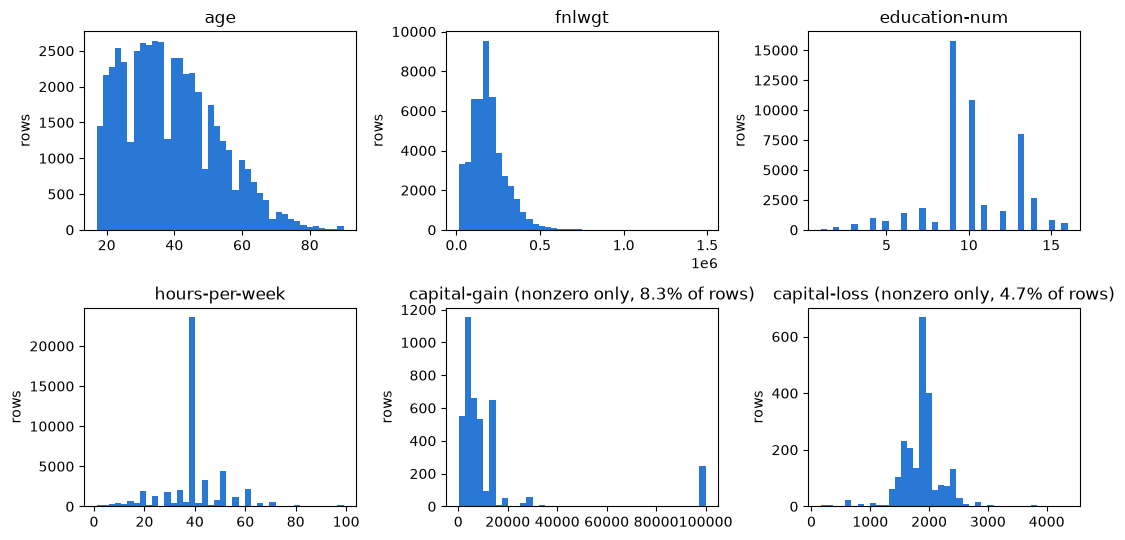

In [6]:
columns = ["age", "fnlwgt", "education-num", "hours-per-week", "capital-gain", "capital-loss"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for ax, col in zip(axes.flat, columns):
    values = df[col]
    title = col
    if col.startswith("capital"):
        title = f"{col} (nonzero only, {(values > 0).mean():.1%} of rows)"
        values = values[values > 0]
    ax.hist(values, bins=40, color="#2a78d6")
    ax.set_title(title)
    ax.set_ylabel("rows")
fig.tight_layout()
plt.show()

The capital columns are mostly zero, so `onehot` applies `log1p` to them.

##### Skewness and outliers

In [7]:
stats = pd.DataFrame({
    "mean": df[numeric].mean(),
    "median": df[numeric].median(),
    "std": df[numeric].std(),
    "skew": df[numeric].skew(),
    "skew after log1p": np.log1p(df[numeric]).skew(),
})

# 1.5 x IQR rule
q1, q3 = df[numeric].quantile(0.25), df[numeric].quantile(0.75)
iqr = q3 - q1
stats["IQR outliers"] = ((df[numeric] < q1 - 1.5 * iqr) | (df[numeric] > q3 + 1.5 * iqr)).sum()

# Many rows at exactly the maximum means the value was capped
stats["max"] = df[numeric].max()
stats["rows at max"] = df[numeric].eq(df[numeric].max()).sum()
print(stats.round(2).to_string())

                     mean    median        std   skew  skew after log1p  IQR outliers      max  rows at max
age                 38.64      37.0      13.71   0.56             -0.11           216       90           55
fnlwgt          189664.13  178144.5  105604.03   1.44             -0.84          1453  1490400            1
education-num       10.08      10.0       2.57  -0.32             -1.74          1794       16          594
capital-gain      1079.07       0.0    7452.02  11.89              3.11          4035    99999          244
capital-loss        87.50       0.0     403.00   4.57              4.30          2282     4356            3
hours-per-week      40.42      40.0      12.39   0.24             -2.35         13496       99          137


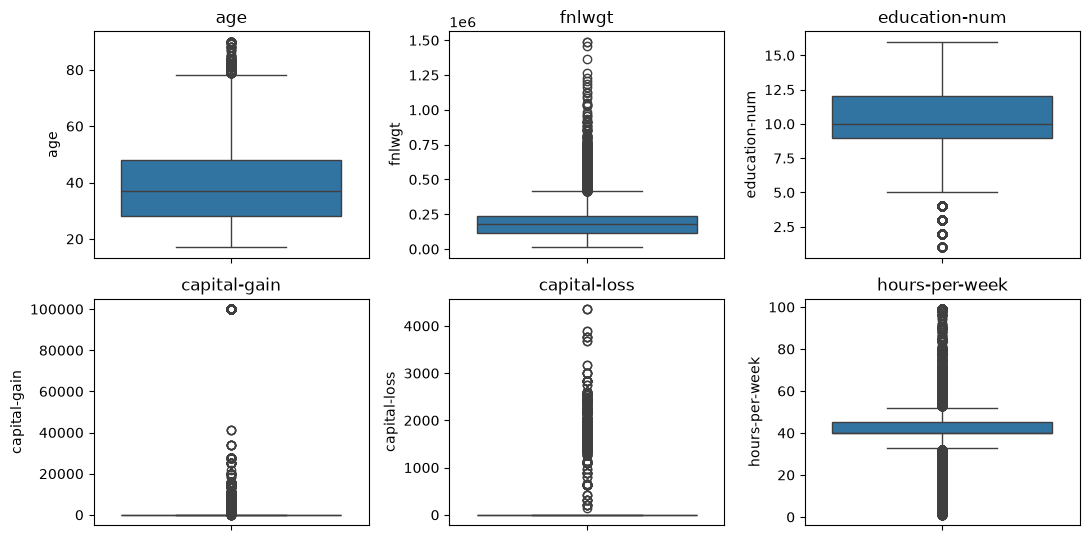

In [8]:
# Box plots: the whiskers end at the 1.5 x IQR bounds, each dot is an outlier
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for ax, col in zip(axes.flat, numeric):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
fig.tight_layout()
plt.show()

In [ ]:
# Rows at exactly each feature's maximum: many rows there means the value was capped
for col in numeric:
    cap = df[col].max()
    print(f"{col:15} cap {cap:>9,}   rows at cap {df[col].eq(cap).sum():>4}")

`capital-gain` is the most skewed (11.9): its median is 0 and 244 rows sit at exactly 99,999, a cap rather than real amounts. Most values are zero, so `log1p` only partly helps (3.1; 4.3 for `capital-loss`) and their boxes are flat lines at 0. `hours-per-week` has the most outliers because so many people work exactly 40 hours that the box is very narrow. We keep all outliers: they are real values.

##### Share of >50K by category

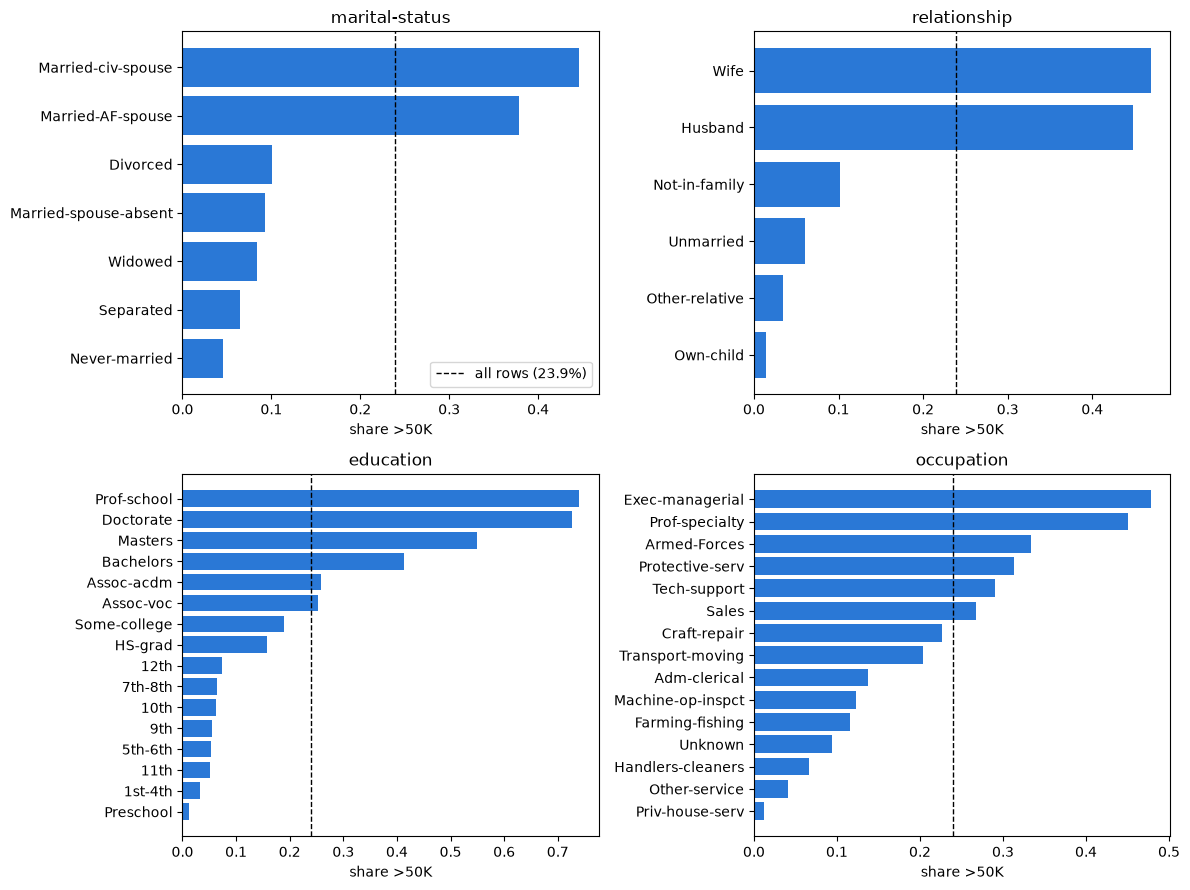

In [9]:
rate = df["income"].mean()
columns = ["marital-status", "relationship", "education", "occupation"]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.flat, columns):
    share = df.groupby(col)["income"].mean().sort_values()
    ax.barh(share.index, share.values, color="#2a78d6")
    ax.axvline(rate, color="black", linestyle="--", linewidth=1, label=f"all rows ({rate:.1%})")
    ax.set_title(col)
    ax.set_xlabel("share >50K")
axes[0, 0].legend()
fig.tight_layout()
plt.show()

Being married, a graduate degree and managerial or professional jobs go with >50K; never-married people and `Own-child` almost never are.

##### Mutual information with income

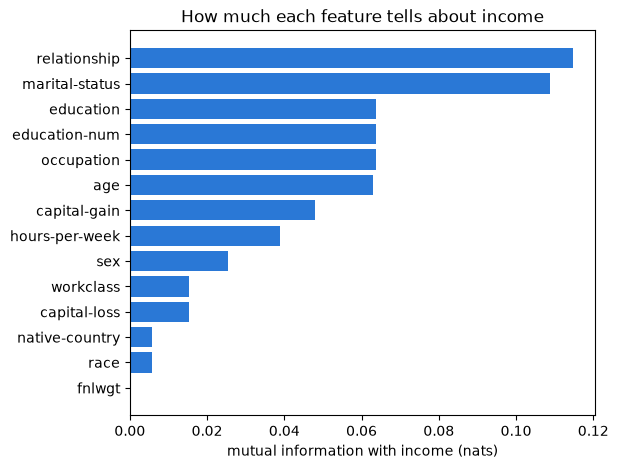

In [10]:
# Same binned features CategoricalNB gets; education-num is already discrete, so keep its 16 values
train_bins, test_bins = to_categories(train, test)
bins = pd.concat([train_bins, test_bins], ignore_index=True)
bins["education-num"] = df["education-num"]

mi = pd.Series({col: mutual_info_score(bins[col], df["income"]) for col in FEATURES}).sort_values()
fig, ax = plt.subplots(figsize=(6, 5))
ax.barh(mi.index, mi.values, color="#2a78d6")
ax.set_xlabel("mutual information with income (nats)")
ax.set_title("How much each feature tells about income")
plt.show()

How much knowing one feature reduces the uncertainty about income (0 = none). Each feature is measured on its own. Naive Bayes adds up their evidence as if they were independent, so features that tell about the same thing get counted twice.

##### Relationship vs sex and marital status

In [11]:
print(pd.crosstab(df["relationship"], df["sex"]).to_string(), "\n")
print(pd.crosstab(df["relationship"], df["marital-status"]).to_string())

sex             Female   Male
relationship                 
Husband              1  19715
Not-in-family     5870   6713
Other-relative     689    817
Own-child         3376   4205
Unmarried         3928   1197
Wife              2328      3 

marital-status  Divorced  Married-AF-spouse  Married-civ-spouse  Married-spouse-absent  Never-married  Separated  Widowed
relationship                                                                                                             
Husband                0                 12               19704                      0              0          0        0
Not-in-family       3628                  0                  23                    330           7114        637      851
Other-relative       181                  1                 201                     54            920         79       70
Own-child            455                  1                 143                     61           6750        146       25
Unmarried           2369  

`Husband` and `Wife` almost fix `sex` and always mean married: a strong dependence, but not a perfect one.

##### Dependence between features (Rish 2001)

Rish found that naive Bayes works best in two opposite cases: completely independent features and functionally dependent features, with its worst performance in between. Adult has both kinds of dependence:

- `education-num` is a function of `education` (functional dependence: 1.00 in the heatmap).
- `Husband` and `Wife` almost fix `sex` and `marital-status`, but the other `relationship` levels don't (0.26 and 0.52 in the heatmap): strong, but not functional, so in between.

The heatmap shows all 91 pairs: 0 means independent, 1 means each feature fixes the other.

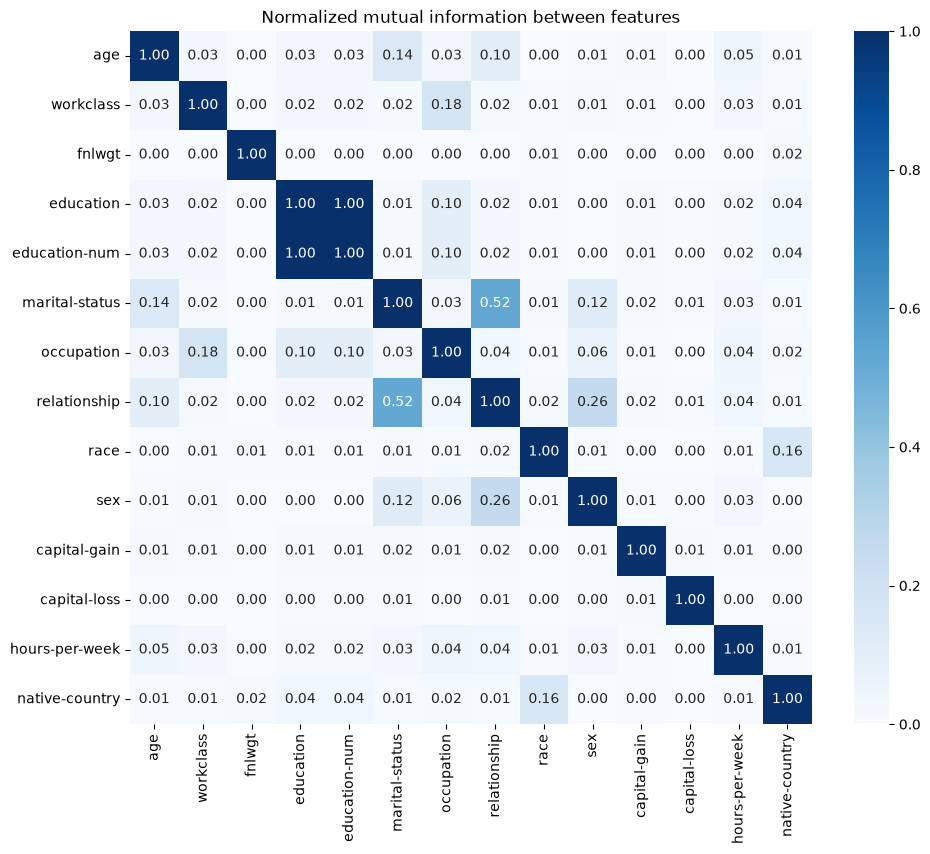

In [12]:
nmi = pd.DataFrame(
    [[normalized_mutual_info_score(bins[a], bins[b]) for b in FEATURES] for a in FEATURES],
    index=FEATURES, columns=FEATURES,
)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(nmi, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Normalized mutual information between features")
plt.show()

This is dependence over all rows. Rish measures it within each class (class-conditional) and finds that information loss predicts naive Bayes accuracy better than dependence does; both come with the information-loss work.